In [5]:
import pandas as pd

df = pd.read_csv('/train.csv')

print("Dataset successfully loaded!")
print("Dataset Shape:", df.shape)

df.head()

Dataset successfully loaded!
Dataset Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
# Dataset ki rows aur columns
print("Dataset Shape:", df.shape)

# Column names aur data types
print("\nDataset Information:")
df.info()

# Missing values check karna
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate rows check karna
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (891, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare     

In [9]:
# Original dataset ki copy banana
df_clean = df.copy()

# Age ko median se fill karna
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())

# Embarked ko mode se fill karna
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

# Cabin column remove karna
df_clean = df_clean.drop(columns=['Cabin'])

# Missing values dobara check karna
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned Dataset Shape:", df_clean.shape)

Missing Values After Cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Cleaned Dataset Shape: (891, 11)


In [10]:
# Unnecessary columns remove karna
df_ml = df_clean.drop(columns=['PassengerId', 'Name', 'Ticket'])

# Categorical columns ko numerical format mein convert karna
df_ml = pd.get_dummies(
    df_ml,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

# Features (X) aur Target (y) alag karna
X = df_ml.drop(columns=['Survived'])
y = df_ml['Survived']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (891, 8)
Target Shape: (891,)

Feature Columns:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']

Target Distribution:
Survived
0    549
1    342
Name: count, dtype: int64


In [11]:
from sklearn.model_selection import train_test_split

# Data ko 80% training aur 20% testing mein divide karna
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (712, 8)
Testing Features: (179, 8)
Training Target: (712,)
Testing Target: (179,)


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Four Machine Learning Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

# Train all models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
SVM trained successfully!


In [13]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 5-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Random Forest ke liye parameter combinations
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}

# Grid Search with Cross Validation
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Model tuning
grid_search.fit(X_train, y_train)

# Best results
best_rf = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 100}
Best Cross-Validation Accuracy: 0.8370530877573131


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Models dictionary mein tuned Random Forest add karna
models["Tuned Random Forest"] = best_rf

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.8045     0.7931  0.6667    0.7244   0.8443
1        Decision Tree    0.8212     0.7937  0.7246    0.7576   0.7949
2        Random Forest    0.8156     0.7812  0.7246    0.7519   0.8344
3                  SVM    0.6201     0.5161  0.2319    0.3200   0.6924
4  Tuned Random Forest    0.8045     0.8400  0.6087    0.7059   0.8374


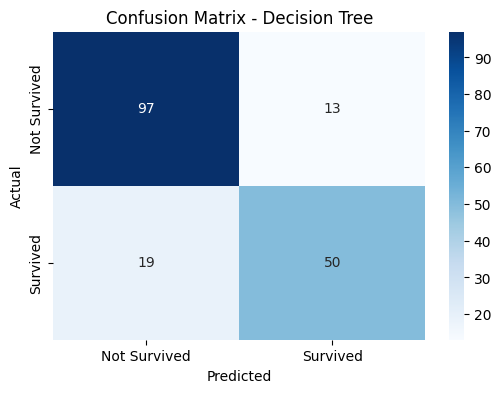

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Best accuracy model: Decision Tree
best_model = models["Decision Tree"]

y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Decision Tree")
plt.show()

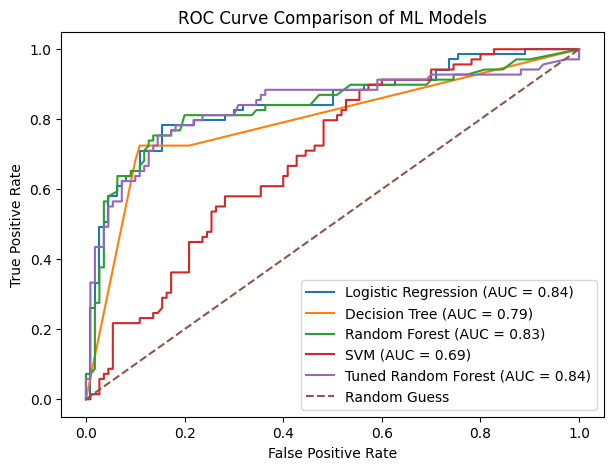

In [16]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of ML Models')
plt.legend()
plt.show()

In [17]:
from sklearn.metrics import classification_report

best_model = models["Decision Tree"]

y_pred = best_model.predict(X_test)

print("FINAL MODEL: DECISION TREE")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Survived", "Survived"]
))

FINAL MODEL: DECISION TREE

Classification Report:
              precision    recall  f1-score   support

Not Survived       0.84      0.88      0.86       110
    Survived       0.79      0.72      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



In [18]:
# Final Model Summary

print("WEEK 4: MACHINE LEARNING PROJECT SUMMARY")
print("-----------------------------------------")

print("Dataset: Titanic Passenger Dataset")
print("Total Records:", len(df_clean))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Number of Features:", X.shape[1])

print("\nModels Compared:")
for name in models.keys():
    print("-", name)

print("\nBest Accuracy Model: Decision Tree")
print("Test Accuracy:", round(
    accuracy_score(y_test, y_pred) * 100, 2
), "%")

print("Best CV Accuracy (Tuned Random Forest):",
      round(grid_search.best_score_ * 100, 2), "%")

WEEK 4: MACHINE LEARNING PROJECT SUMMARY
-----------------------------------------
Dataset: Titanic Passenger Dataset
Total Records: 891
Training Records: 712
Testing Records: 179
Number of Features: 8

Models Compared:
- Logistic Regression
- Decision Tree
- Random Forest
- SVM
- Tuned Random Forest

Best Accuracy Model: Decision Tree
Test Accuracy: 82.12 %
Best CV Accuracy (Tuned Random Forest): 83.71 %


In [19]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=['Survived', 'PassengerId', 'Name', 'Ticket', 'Cabin'])
y = df['Survived']

# Split data before preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (712, 7)
Testing data shape: (179, 7)


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Sex', 'Embarked']

# Preprocessing for numerical data
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing for categorical data
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create model pipeline
decision_tree_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])

# Train the model
decision_tree_pipeline.fit(X_train, y_train)

# Predict on test data
y_pred = decision_tree_pipeline.predict(X_test)

# Evaluate model
print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Decision Tree Accuracy: 0.8156424581005587

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       110
           1       0.79      0.71      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

logistic_pipeline.fit(X_train, y_train)

y_pred_lr = logistic_pipeline.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.8044692737430168

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

random_forest_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

random_forest_pipeline.fit(X_train, y_train)

y_pred_rf = random_forest_pipeline.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.8156424581005587

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.86       110
           1       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



In [25]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', SVC(probability=True, random_state=42))
])

svm_pipeline.fit(X_train, y_train)

y_pred_svm = svm_pipeline.predict(X_test)

print("SVM Accuracy:",
      accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.8156424581005587

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.91      0.86       110
           1       0.82      0.67      0.74        69

    accuracy                           0.82       179
   macro avg       0.82      0.79      0.80       179
weighted avg       0.82      0.82      0.81       179



In [26]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 5, 10],
    'model__min_samples_split': [2, 5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    rf_pipeline,
    param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Best Cross-Validation Accuracy: 0.8174332709543977


In [27]:
best_rf = grid_search.best_estimator_

# Predict on unseen test data
y_pred_tuned = best_rf.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Tuned Random Forest Test Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

print("ROC-AUC Score:",
      roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1]))

Tuned Random Forest Test Accuracy: 0.8100558659217877

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.91      0.85       110
           1       0.82      0.65      0.73        69

    accuracy                           0.81       179
   macro avg       0.81      0.78      0.79       179
weighted avg       0.81      0.81      0.81       179

Confusion Matrix:
[[100  10]
 [ 24  45]]
ROC-AUC Score: 0.8328063241106719


In [28]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
import pandas as pd

models = {
    "Decision Tree": (decision_tree_pipeline, y_pred),
    "Logistic Regression": (logistic_pipeline, y_pred_lr),
    "Random Forest": (random_forest_pipeline, y_pred_rf),
    "SVM": (svm_pipeline, y_pred_svm),
    "Tuned Random Forest": (best_rf, y_pred_tuned)
}

results = []

for name, (model, predictions) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(
            y_test, model.predict_proba(X_test)[:, 1]
        )
    })

comparison_df = pd.DataFrame(results)
print(comparison_df.round(3).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
      Decision Tree     0.816      0.790   0.710     0.748    0.790
Logistic Regression     0.804      0.793   0.667     0.724    0.844
      Random Forest     0.816      0.800   0.696     0.744    0.829
                SVM     0.816      0.821   0.667     0.736    0.840
Tuned Random Forest     0.810      0.818   0.652     0.726    0.833


In [31]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Select numerical features
vif_data = X_train[
    ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
].copy()

# Handle missing and infinite values
vif_data = vif_data.replace([float('inf'), float('-inf')], float('nan'))
vif_data = vif_data.fillna(vif_data.median())

# Calculate VIF
vif_result = pd.DataFrame()
vif_result['Feature'] = vif_data.columns

vif_result['VIF'] = [
    variance_inflation_factor(vif_data.values, i)
    for i in range(vif_data.shape[1])
]

print(vif_result.round(3))

  Feature    VIF
0  Pclass  1.651
1     Age  1.180
2   SibSp  1.250
3   Parch  1.225
4    Fare  1.571


Survival Class Distribution:
Survived
0    439
1    273
Name: count, dtype: int64

Percentage Distribution:
Survived
0    61.66
1    38.34
Name: proportion, dtype: float64


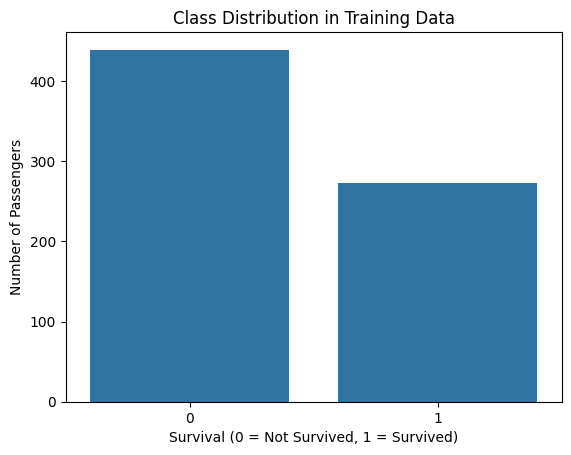

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check target class distribution
print("Survival Class Distribution:")
print(y_train.value_counts())

print("\nPercentage Distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

# Visualize class distribution
sns.countplot(x=y_train)
plt.title("Class Distribution in Training Data")
plt.xlabel("Survival (0 = Not Survived, 1 = Survived)")
plt.ylabel("Number of Passengers")
plt.show()

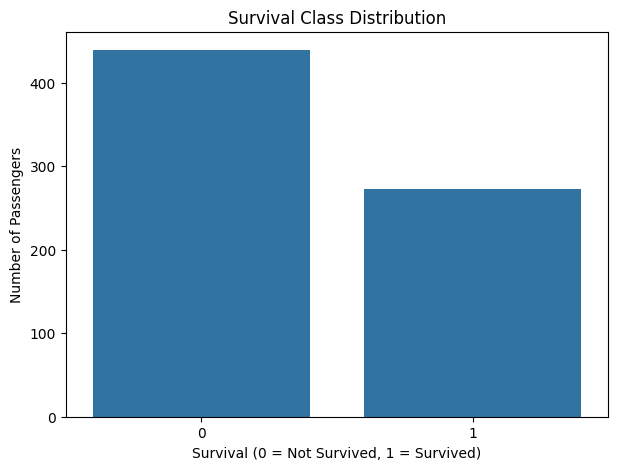

In [33]:
plt.figure(figsize=(7, 5))

sns.countplot(x=y_train)

plt.title("Survival Class Distribution")
plt.xlabel("Survival (0 = Not Survived, 1 = Survived)")
plt.ylabel("Number of Passengers")

plt.savefig("class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

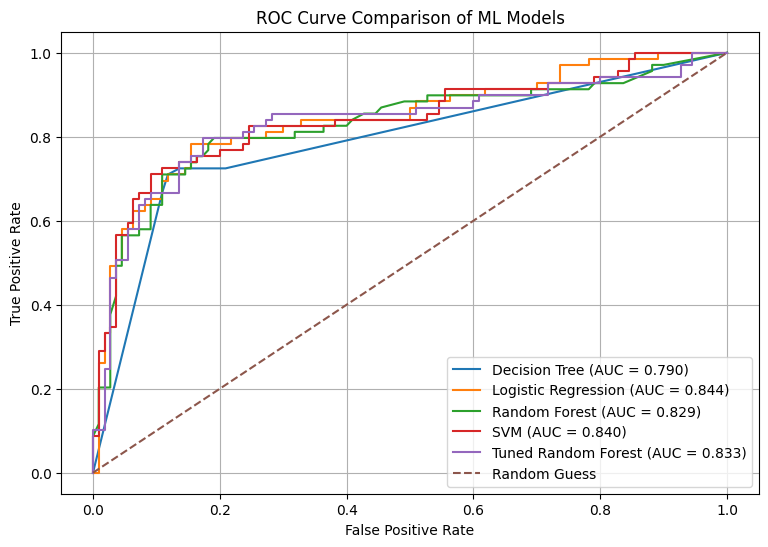

In [34]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

models_to_plot = {
    "Decision Tree": decision_tree_pipeline,
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline,
    "SVM": svm_pipeline,
    "Tuned Random Forest": best_rf
}

plt.figure(figsize=(9, 6))

for name, model in models_to_plot.items():
    y_probability = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_probability)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of ML Models")
plt.legend()
plt.grid()
plt.savefig("roc_curve_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion

In this project, machine learning classification models were developed to predict passenger survival using the Titanic dataset.

The dataset contained 891 records. Missing values were handled using median imputation for numerical data and mode imputation for categorical data. The Cabin column was removed due to a large number of missing values. Categorical features were encoded, and numerical features were standardized.

The dataset was divided into 80% training data and 20% testing data. Five models were evaluated: Decision Tree, Logistic Regression, Random Forest, SVM, and Tuned Random Forest.

Decision Tree, Random Forest, and SVM achieved the highest test accuracy of approximately 81.56%. Logistic Regression achieved the highest ROC-AUC score of approximately 84.43%. After hyperparameter tuning, Random Forest achieved a cross-validation accuracy of approximately 81.74%.

The VIF analysis showed that all selected numerical features had VIF values below 2, indicating no serious multicollinearity among them. The target variable showed moderate class imbalance, with 61.66% non-survivors and 38.34% survivors in the training data.

Overall, the models demonstrated reasonable predictive performance. Future improvements could include additional feature engineering, testing other algorithms, and using more advanced hyperparameter optimization techniques.